In [96]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix



In [97]:
data = load_breast_cancer()

X = pd.DataFrame(
    data.data,
    columns = data.feature_names
)

y = pd.Series(
    (data.target == 0).astype(int),
    name = "malignant"   
)

print(y.value_counts())
print("Feature matrix shape",X.shape)
print("target shape", y.shape)
print("class names",data.target_names)

malignant
0    357
1    212
Name: count, dtype: int64
Feature matrix shape (569, 30)
target shape (569,)
class names ['malignant' 'benign']


In [98]:
class_counts = y.value_counts().sort_index()
class_distribution = pd.DataFrame({"Class" : data.target_names,
    "Count" : class_counts.values,
    "Probablity" : class_counts.values/len(y)}
)

print(class_distribution)

       Class  Count  Probablity
0  malignant    357    0.627417
1     benign    212    0.372583


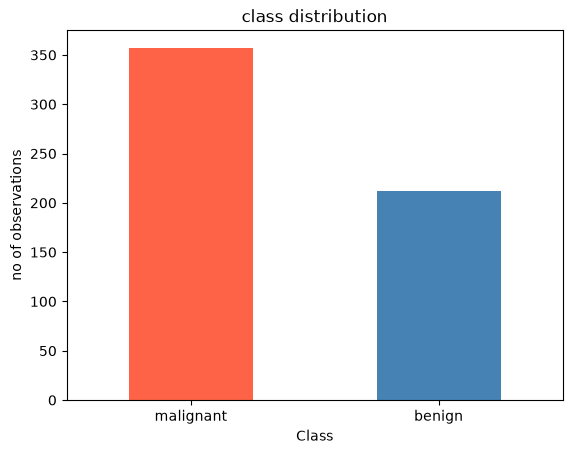

In [99]:
class_distribution.plot(
    x="Class",
    y="Count",
    kind="bar",
    legend=False,
    color=["tomato","steelblue"]
)

plt.ylabel("no of observations")
plt.title("class distribution")
plt.xticks(rotation=0)
plt.show()

In [100]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.20, random_state = 42, stratify = y)

print("training size", len(y_train))
print("testing size",len(y_test))

print("\ntraining proportions")
print(y_train.value_counts(normalize=True).sort_index())

print("\n testing proportions")
print(y_test.value_counts(normalize=True).sort_index())

training size 455
testing size 114

training proportions
malignant
0    0.626374
1    0.373626
Name: proportion, dtype: float64

 testing proportions
malignant
0    0.631579
1    0.368421
Name: proportion, dtype: float64


In [101]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [102]:
probablities = model.predict_proba(X_test)

print(probablities[:5])

[[9.99635432e-01 3.64568116e-04]
 [1.07465986e-08 9.99999989e-01]
 [9.57432053e-01 4.25679471e-02]
 [4.23812678e-01 5.76187322e-01]
 [4.90844511e-01 5.09155489e-01]]


In [103]:
print(probablities[:5].sum(axis=1))

[1. 1. 1. 1. 1.]


In [104]:
results = pd.DataFrame({"actual_class": y_test.values,
    "P_malignant": probablities[:,0],
    "P_benign": probablities[:,1]}
    
)
print(results.head(10))

   actual_class   P_malignant  P_benign
0             0  9.996354e-01  0.000365
1             1  1.074660e-08  1.000000
2             0  9.574321e-01  0.042568
3             1  4.238127e-01  0.576187
4             0  4.908445e-01  0.509155
5             0  9.993840e-01  0.000616
6             1  2.384659e-01  0.761534
7             0  9.989878e-01  0.001012
8             0  9.994313e-01  0.000569
9             0  9.892324e-01  0.010768


In [105]:
results["Actual_label"] = results["actual_class"].map({
    0: "Malignant",
    1: "Benign"
})

print(
    results[
        ["Actual_label","P_malignant","P_benign"]
    ].head(10)
)

  Actual_label   P_malignant  P_benign
0    Malignant  9.996354e-01  0.000365
1       Benign  1.074660e-08  1.000000
2    Malignant  9.574321e-01  0.042568
3       Benign  4.238127e-01  0.576187
4    Malignant  4.908445e-01  0.509155
5    Malignant  9.993840e-01  0.000616
6       Benign  2.384659e-01  0.761534
7    Malignant  9.989878e-01  0.001012
8    Malignant  9.994313e-01  0.000569
9    Malignant  9.892324e-01  0.010768


In [117]:
threshold = 0.60

results["Predicted_malignant"]=(
    results["P_malignant"] >= threshold
).astype(int)

results["Predicted_label"]= results[
    "Predicted_malignant"
].map({
    1 : "Malignant",
    0 : "Benign"
})

print(
    results[
        [
            "Actual_label",
            "P_malignant",
            "Predicted_label"
        ]
    ].head(10)
)


  Actual_label   P_malignant Predicted_label
0    Malignant  9.996354e-01       Malignant
1       Benign  1.074660e-08          Benign
2    Malignant  9.574321e-01       Malignant
3       Benign  4.238127e-01          Benign
4    Malignant  4.908445e-01          Benign
5    Malignant  9.993840e-01       Malignant
6       Benign  2.384659e-01          Benign
7    Malignant  9.989878e-01       Malignant
8    Malignant  9.994313e-01       Malignant
9    Malignant  9.892324e-01       Malignant


In [118]:
for threshold in [0.60, 0.80, 0.90]:
    predictions = (
        results["P_malignant"] >= threshold
    ).astype(int)
    
    print(
        f"Threshold = {threshold}:"
        f"Predicted malignant cases = {predictions.sum()}"
    )

Threshold = 0.6:Predicted malignant cases = 73
Threshold = 0.8:Predicted malignant cases = 69
Threshold = 0.9:Predicted malignant cases = 68


In [119]:
# Construct a confusion matrix

actual_malignant = (y_test.values == 0).astype(int)
for threshold in[0.50, 0.60, 0.90]:
    predicted_malignant = (
        probablities[:,0] >= threshold
    ).astype(int)
    
    cm = confusion_matrix(
        actual_malignant,
        predicted_malignant
    )
    print(f"\n Threshold = {threshold}")
    print(cm)


 Threshold = 0.5
[[39  3]
 [ 1 71]]

 Threshold = 0.6
[[40  2]
 [ 1 71]]

 Threshold = 0.9
[[41  1]
 [ 5 67]]


In [120]:
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
print("sklearn accuracy:", accuracy_score(y_test, predictions))

print("sklearn precision:", precision_score(y_test,predictions))

print("sklearn recall",recall_score(y_test,predictions))

print("sklearn f1 score", f1_score(y_test,predictions))

sklearn accuracy: 0.05263157894736842
sklearn precision: 0.014705882352941176
sklearn recall 0.023809523809523808
sklearn f1 score 0.01818181818181818


In [ ]:
metrics_results=[]

for threshold in [0.10, 0.30, 0.50,0.70,0.90]:
    y_pred_threshold = (
        probablities[:,1] >= threshold
    ).astype(int)
    
    tn, fp ,fn, tp = confusion_matrix(y_test,y_pred_threshold,labels=[0,1]).ravel()
    
    accuracy = (tp+tn)